# Netflix catalogue: format, geography and release history

The aim is to describe the titles present in the uploaded Netflix snapshot: their formats, listed countries, categories and release history. The date a title was added is kept separate from the year it was originally released.

## Data and scope

Source: [netflix-shows](https://www.kaggle.com/datasets/shivamb/netflix-shows). This report uses the uploaded snapshot, not live data.

One row represents one catalogue title. `show_id` is its identifier; `type` separates Movie and TV Show; `title` is the name. `country`, `director`, `cast` and `listed_in` may contain comma-separated values. `date_added` is the addition date; `release_year` is the original release year. `rating` is an audience classification. `duration` mixes movie minutes and TV season counts; these need separate numeric columns. `description` is a synopsis.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 25)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def data_path(filename):
    # Works after extracting this ZIP, or after attaching its data on Kaggle.
    for folder in (Path("data"), Path(".")):
        candidate = folder / filename
        if candidate.is_file():
            return candidate
    kaggle = Path("/kaggle/input")
    matches = sorted(kaggle.rglob(filename)) if kaggle.exists() else []
    if len(matches) == 1:
        return matches[0]
    raise FileNotFoundError(f"Place {filename} in data/, or attach its dataset on Kaggle. Found {len(matches)} Kaggle matches.")

In [2]:
raw = pd.read_csv(data_path("netflix_titles.csv"))
print(f"Raw file: {len(raw):,} titles, {raw.shape[1]} columns")
assert len(raw)>=150 and raw.shape[1]>=3
display(raw.head()); display(raw.isna().sum().to_frame("missing"))

Raw file: 8,807 titles, 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


,missing
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


## Cleaning dates and mixed duration fields

Some entries have a minute value in `rating` and no `duration`. Those values are moved only when that exact pattern is present. `str.extract()` pulls numbers from duration strings, and `where()` keeps minutes and season counts separate. Missing directors, casts and countries are retained; deleting those rows would remove usable titles. `to_datetime()` parses addition dates, leaving failed conversions visible as missing.

Misplaced durations repaired: 3; duplicate IDs: 0; missing addition dates: 10
Addition dates: 2008-01-01 to 2021-09-25


,count,mean,std,min,25%,50%,75%,max
release_year,"8,807.000","2,014.180",8.819,"1,925.000","2,013.000","2,017.000","2,019.000","2,021.000"
movie_minutes,"6,131.000",99.565,28.290,3.000,87.000,98.000,114.000,312.000
tv_seasons,"2,676.000",1.765,1.583,1.000,1.000,1.000,2.000,17.000
addition_lag,"8,797.000",4.688,8.787,-3.000,0.000,1.000,5.000,93.000


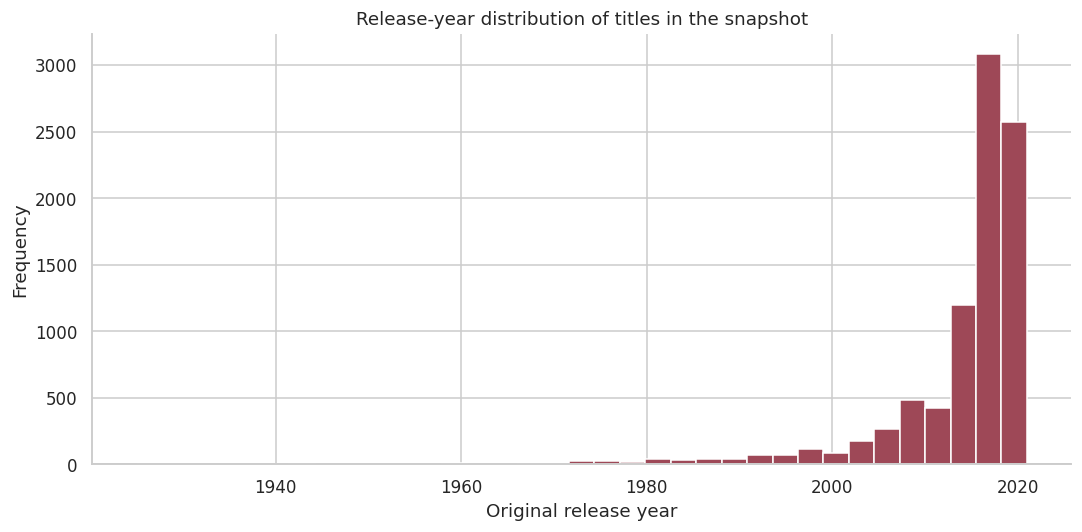

In [3]:
df = raw.drop_duplicates().copy()
misplaced = df.rating.astype("string").str.fullmatch(r"\d+ min",na=False) & df.duration.isna()
df.loc[misplaced,"duration"] = df.loc[misplaced,"rating"]
df.loc[misplaced,"rating"] = pd.NA
df["date_added"] = pd.to_datetime(df.date_added.astype("string").str.strip(),format="%B %d, %Y",errors="coerce")
df["added_year"] = df.date_added.dt.year.astype("Int64")
duration = pd.to_numeric(df.duration.astype("string").str.extract(r"(\d+)",expand=False),errors="coerce")
df["movie_minutes"] = duration.where(df.type.eq("Movie"))
df["tv_seasons"] = duration.where(df.type.eq("TV Show"))
df["addition_lag"] = df.added_year-df.release_year
print(f"Misplaced durations repaired: {misplaced.sum()}; duplicate IDs: {df.show_id.duplicated().sum()}; missing addition dates: {df.date_added.isna().sum()}")
print(f"Addition dates: {df.date_added.min().date()} to {df.date_added.max().date()}")
display(df[["release_year","movie_minutes","tv_seasons","addition_lag"]].describe().T)
df.release_year.plot.hist(bins=35,color="#9e4857")
plt.xlabel("Original release year"); plt.title("Release-year distribution of titles in the snapshot"); plt.tight_layout(); plt.show()

## 1. What is the balance between films and television series?

`value_counts()` gives the number of titles in each format. Percentages use all titles as the denominator; one series counts as one title regardless of its season count.

,titles,share_pct
type,,
Movie,6131,69.615
TV Show,2676,30.385


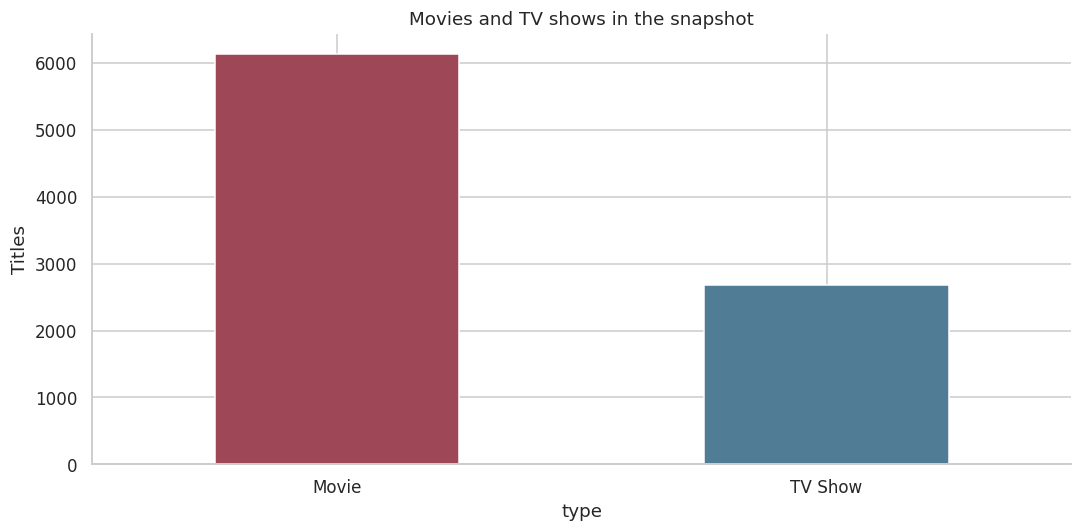

In [4]:
formats = df.type.value_counts()
display(pd.DataFrame({"titles":formats,"share_pct":formats/len(df)*100}))
formats.plot.bar(color=["#9e4857","#507d95"],rot=0)
plt.ylabel("Titles"); plt.title("Movies and TV shows in the snapshot"); plt.tight_layout(); plt.show()

**Answer.** Movie titles form the larger group: 6,131, or 69.6% of the catalogue snapshot. This is a count of catalogue entries, not viewing time or audience demand.

## 2. Which countries are associated with the most titles?

`str.split()` and `explode()` create one title-country row for each listed country. Each title is counted once per country; a co-production can therefore contribute to several countries. Missing country metadata is excluded from this question only.

,associated_titles
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


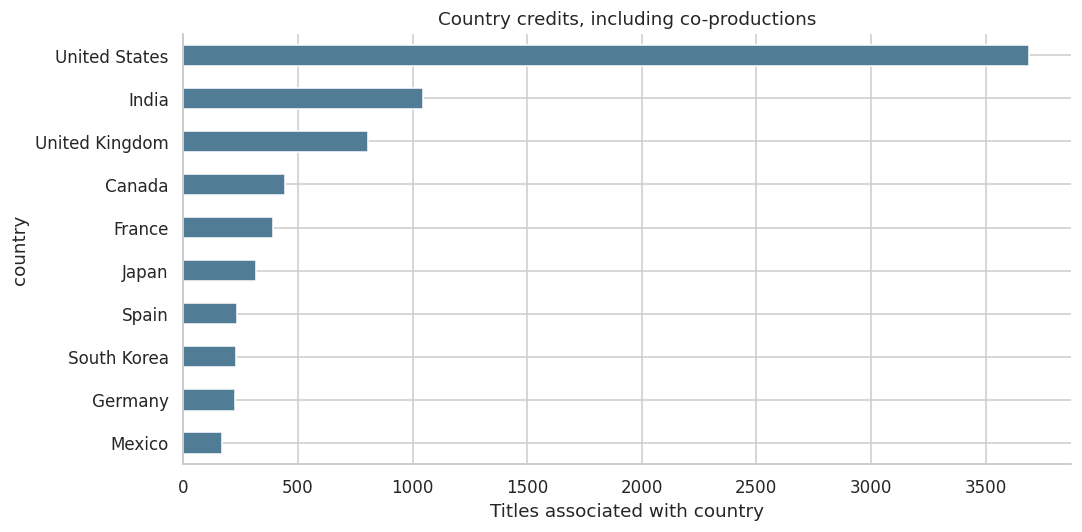

In [5]:
country_rows = df.dropna(subset=["country"])[["show_id","country"]].copy()
country_rows["country"] = country_rows.country.str.split(",")
country_rows = country_rows.explode("country")
country_rows["country"] = country_rows.country.str.strip()
countries = country_rows.drop_duplicates(["show_id","country"]).country.value_counts()
display(countries.head(12).to_frame("associated_titles"))
countries.head(10).sort_values().plot.barh(color="#507d95")
plt.xlabel("Titles associated with country"); plt.title("Country credits, including co-productions"); plt.tight_layout(); plt.show()

**Answer.** United States is associated with 3,690 titles, the largest count. Country information is missing for 831 titles. Since co-productions appear under each listed country, these counts should not be added to estimate catalogue size.

## 3. How do recorded additions change over time?

`crosstab()` counts formats by addition year. The last year is displayed but flagged as incomplete whenever the file ends before December. These additions describe titles still present in the snapshot, so they do not reconstruct every historical addition or removal.

type,Movie,TV Show
added_year,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,253,176


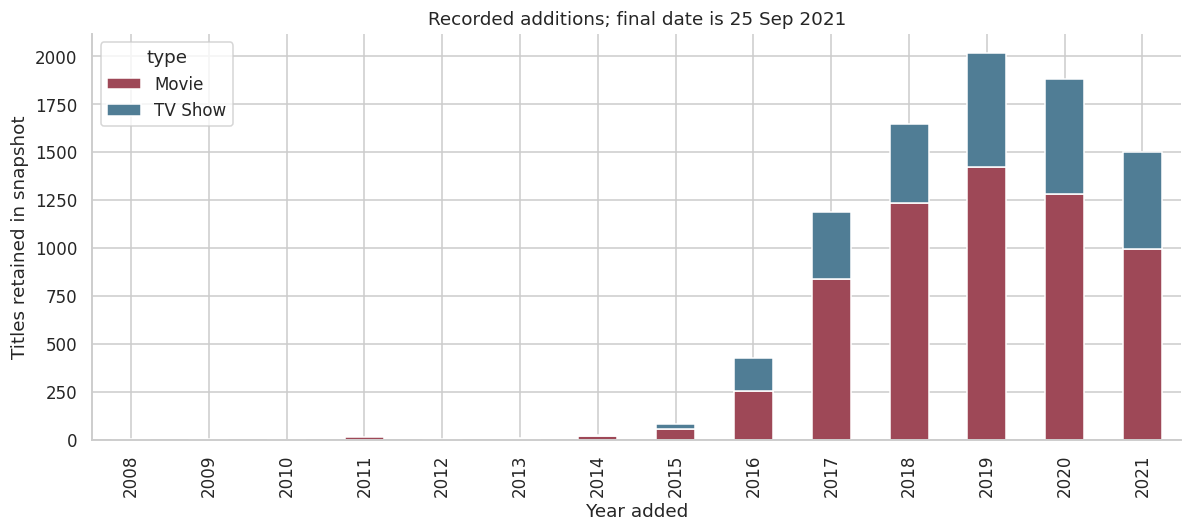

In [6]:
additions = pd.crosstab(df.added_year,df.type)
display(additions)
additions.plot.bar(stacked=True,color=["#9e4857","#507d95"],figsize=(11,5))
plt.xlabel("Year added"); plt.ylabel("Titles retained in snapshot")
plt.title(f"Recorded additions; final date is {df.date_added.max():%d %b %Y}")
plt.tight_layout(); plt.show()

**Answer.** 2019 has the most recorded additions (2,016). The file ends on 25 September 2021; the final year is not a full-year comparison. Removed titles are absent, so these figures are not a complete history of platform growth.

## 4. Which catalogue categories are most common?

Category labels are split and counted separately. A title can belong to several categories, so this answers which labels are common rather than assigning each title to a single exclusive genre.

,titles
category,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


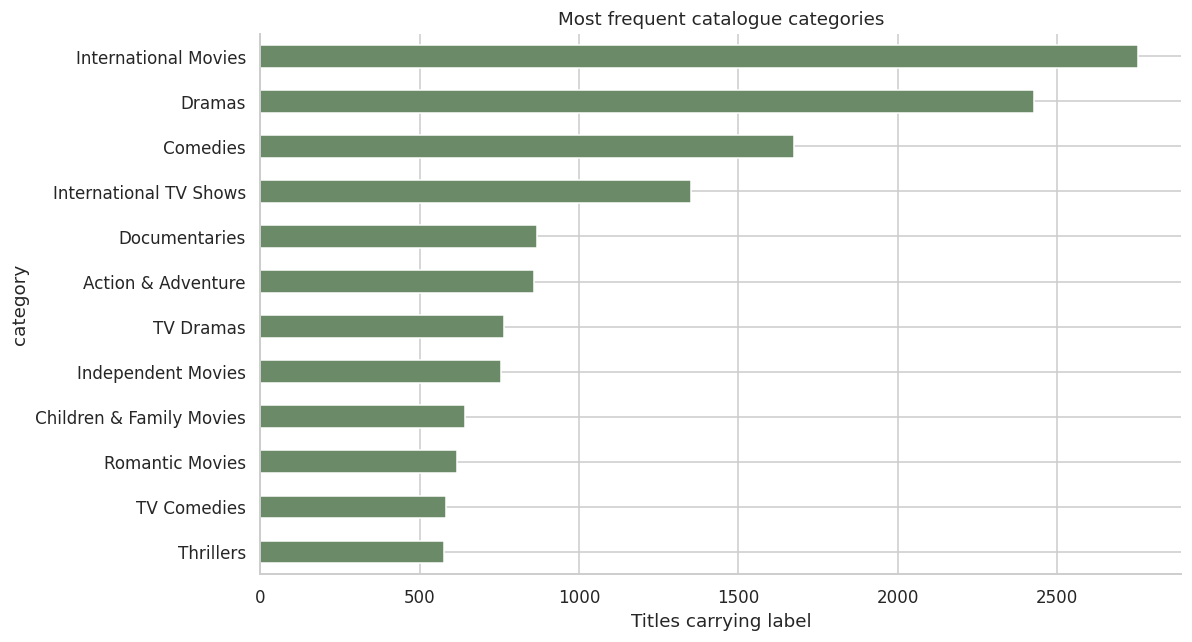

In [7]:
category_rows = df[["show_id","listed_in"]].dropna().copy()
category_rows["category"] = category_rows.listed_in.str.split(",")
category_rows = category_rows.explode("category")
category_rows["category"] = category_rows.category.str.strip()
categories = category_rows.drop_duplicates(["show_id","category"]).category.value_counts()
display(categories.head(12).to_frame("titles"))
categories.head(12).sort_values().plot.barh(color="#6a8a68",figsize=(11,6))
plt.xlabel("Titles carrying label"); plt.title("Most frequent catalogue categories"); plt.tight_layout(); plt.show()

**Answer.** International Movies is the most frequent category label, attached to 2,752 titles. Labels such as international films and dramas overlap, so the category totals are not mutually exclusive market shares.

## 5. How long are films, and how many seasons do series have?

Separate plots avoid comparing minutes with seasons. `median()` describes the middle entry in each format. The table includes nonmissing counts so the size of each comparison is clear.

movie_minutes                    tv_seasons                   
                count median   min   max      count median   min   max
type                                                                  
Movie            6131 98.000     3   312          0   <NA>  <NA>  <NA>
TV Show             0   <NA>  <NA>  <NA>       2676  1.000     1    17

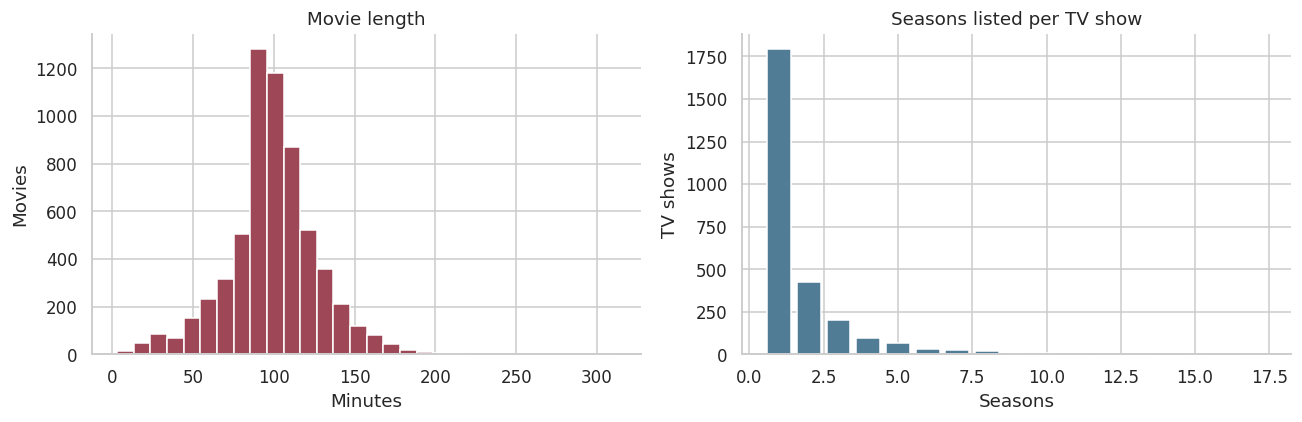

In [8]:
movie = df.movie_minutes.dropna()
seasons = df.tv_seasons.dropna()
display(df.groupby("type")[["movie_minutes","tv_seasons"]].agg(["count","median","min","max"]))
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].hist(movie,bins=30,color="#9e4857")
axes[0].set(xlabel="Minutes",ylabel="Movies",title="Movie length")
season_counts = seasons.value_counts().sort_index()
axes[1].bar(season_counts.index,season_counts.values,color="#507d95")
axes[1].set(xlabel="Seasons",ylabel="TV shows",title="Seasons listed per TV show")
plt.tight_layout(); plt.show()

**Answer.** The median movie length is 98 minutes across 6,131 films with duration data. The median TV-show season count is 1, across 2,676 shows. Season counts do not reveal episode counts or total running time.